# Сравнение реализаций kNN: scikit-learn и FAISS

Сравним точный поиск ближайших соседей в `KNeighborsClassifier` с тремя стратегиями scikit-learn: полный перебор (`brute`), `kd_tree` и `ball_tree`. Эксперимент повторяется для разной размерности данных: деревья обычно эффективнее в низкой размерности, а при росте числа признаков их преимущество может исчезать.

Отдельно сравним с точным CPU-индексом FAISS `IndexFlatL2`. Он тоже перебирает векторы, но использует оптимизированную реализацию. FAISS не входит в стандартный набор scikit-learn и в текущем kernel не установлен. Чтобы выполнить последнюю ячейку, установите пакет командой `%pip install faiss-cpu`, затем перезапустите kernel.

Время зависит от процессора, числа потоков и версий библиотек. Сравниваем одинаковые данные и `k=5`; времена обучения индекса и поиска измеряются раздельно.

In [80]:
from datasets import load_dataset
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import matplotlib.pyplot as plt
import os

In [81]:
if os.path.exists("X.npy") and os.path.exists("y.npy"):
    X, y = np.load("X.npy"), np.load("y.npy")
else:
    trainset = load_dataset("phystech/cifar_train", token=None, split='train')
    X, y = np.stack([x['data'] for x in tqdm(trainset)]), np.stack([x['label'] for x in tqdm(trainset)])
    np.save("X.npy", X)
    np.save("y.npy", y)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [47]:
print(f'Dimensionality: {X_train.shape[1]}')
print(f'X_train size: {X_train.shape[0]:,}')
print(f'X_test size: {X_test.shape[0]:,}')

Dimensionality: 768
X_train size: 40,000
X_test size: 10,000


<Axes: title={'center': 'Train and Test Class Distribution'}, xlabel='Class', ylabel='Count'>

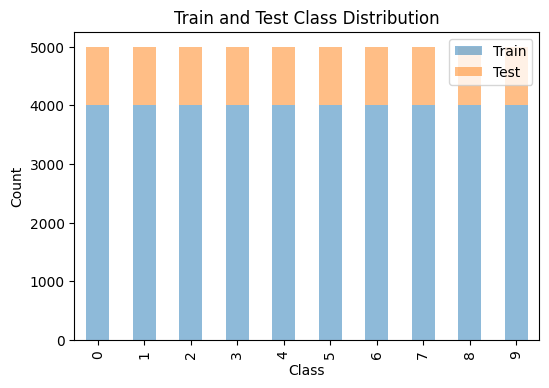

In [82]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
train_classes, train_counts = np.unique(y_train, return_counts=True)
test_classes, test_counts = np.unique(y_test, return_counts=True)

distr = pd.DataFrame({'Train': train_counts, 'Test': test_counts}, index=train_classes)

distr.plot(kind='bar', ax=ax, stacked=True, title='Train and Test Class Distribution', xlabel='Class', ylabel='Count', alpha=0.5)

In [83]:
from sklearn.neighbors import KNeighborsClassifier

In [84]:
model = KNeighborsClassifier(
    n_neighbors=10,
    algorithm='brute',
    metric="euclidean",
    n_jobs=-1,
)

In [85]:
model.fit(X_train, y_train)

KNeighborsClassifier(algorithm='brute', metric='euclidean', n_jobs=-1,
                     n_neighbors=10)

In [86]:
y_pred = model.predict(X_test)

In [87]:
(y_pred==y_test).mean()

0.6677

In [88]:
import faiss

In [89]:
index = faiss.IndexFlatL2(768)
index.add(X_train)

In [91]:
distances, indices = index.search(X_test, k=10)
y_pred = np.apply_along_axis(lambda x: np.bincount(x).argmax(), axis=1, arr=y_train[indices])

(y_pred == y_test).mean()

0.6677

In [92]:
quantizer=faiss.IndexFlatL2(768) # индекс для хранения центроидов кластеров
d=768
nlist=100
metric=faiss.METRIC_L2

index = faiss.IndexIVFFlat(quantizer, d, nlist, metric)

index.train(X_train)  # Обучаем разбиение на кластеры
index.add(X_train)    # Распределяем векторы по кластерам

In [104]:
index.nprobe = 5  # Количество кластеров, которые будут использоваться при поиске

distances, indices = index.search(X_test, k=10)
y_pred = np.apply_along_axis(lambda x: np.bincount(x).argmax(), axis=1, arr=y_train[indices])

(y_pred == y_test).mean()

0.6618

In [68]:
X_train.shape[0] / nlist

400.0

Минимум объектов: 1
Максимум объектов: 1963
Среднее число объектов: 400.0


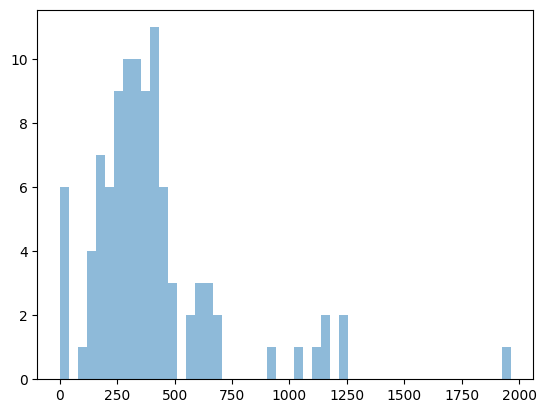

In [69]:
_, assignments = index.quantizer.search(X_train, 1)
assignments = assignments.ravel()

counts = np.bincount(assignments, minlength=index.nlist)

print("Минимум объектов:", counts.min())
print("Максимум объектов:", counts.max())
print("Среднее число объектов:", counts.mean())

plt.hist(counts, bins=50, alpha=0.5);

In [117]:
d=768
M=64
metric=faiss.METRIC_L2

index = faiss.IndexHNSWFlat(d, M, metric)

index.hnsw.efConstruction = 200
index.add(X_train)

In [120]:
index.hnsw.efSearch = 256

distances, indices = index.search(X_test, k=10)
y_pred = np.apply_along_axis(lambda x: np.bincount(x).argmax(), axis=1, arr=y_train[indices])

(y_pred == y_test).mean()

0.6668